# İstanbul Su Kaynakları, Baraj Doluluk Oranları ve İklim Faktörleri Kapsamlı Veri Analizi Projesi

**Proje Amacı:** Bu çalışmada, İstanbul'un su güvenliği, baraj doluluk oranlarının yıllara ve aylara göre değişimi, iklimsel faktörler (ortalama sıcaklıklar, yağışlar ve buharlaşma potansiyeli) ile doluluk oranları arasındaki korelasyonlar incelenmiştir. Ayrıca projede aktif olarak kullanılan veri setlerinin envanteri, her analiz öncesi sunulan özet tablolar, grafikler, markdown analitik değerlendirmeleri ve referans kaynaklar bu raporda yer almaktadır.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Grafik ve Görselleştirme Stili Ayarları
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
sns.set_theme(style="whitegrid", palette="muted")
import warnings
warnings.filterwarnings('ignore')

## 1. Projede Aktif Olarak Kullanılan Veri Setleri Envanteri ve Amaçları
Bu analiz çalışmasında, İstanbul'un su kaynaklarını ve iklimsel etkilerini çok boyutlu ele alabilmek için projede doğrudan kodla işlenen **4 veri seti** kullanılmıştır: baraj doluluklarına ait 3 veri seti (dolulukorani.com) ve İstanbul'a ait günlük hava verilerini içeren 1 meteoroloji veri seti (Open-Meteo Historical Weather API). Tüm veri setleri CSV dosyası olarak indirilmiş ve notebook'a kaynaktan geldiği haliyle okunmuştur.

**Not:** Meteoroloji Genel Müdürlüğü'nün (MGM) il istatistikleri sayfası yalnızca uzun dönem (1950-2025) aylık ortalamalarını verdiği için yıllara göre karşılaştırma yapmaya uygun değildir. Bu nedenle yıl ve ay bazında günlük veri sunan Open-Meteo veri seti tercih edilmiştir.

Aşağıdaki tablo, kullanılan verilerin proje içerisindeki rolünü ve hangi amaçla kullanıldığını açıklamaktadır:

In [2]:
# Projede aktif kullanılan veri setleri envanter tablosunun oluşturulması
active_inventory_data = {
    'Dosya Adı': [
        'baraj-yillik-doluluk.csv',
        'baraj-doluluk-istanbul-1100g.csv',
        'barajlar.csv',
        'open-meteo-41.02N28.89E32m.csv'   # YENİ: meteoroloji veri seti
    ],
    'Veri Türü': [
        'CSV (Yapılandırılmış Yıllık Zaman Serisi)',
        'CSV (Günlük Zaman Serisi)',
        'CSV (Baraj Detay ve Anlık Doluluk Tablosu)',
        'CSV (Günlük Meteoroloji Zaman Serisi)'   # YENİ
    ],
    'Kapsam ve Kullanım Amacı': [
        'Türkiye geneli ve İstanbul barajlarının 2010-2024 yılları arasındaki yıllık doluluk oranlarını sağlar. Tarihsel trend analizinin temelidir.',
        'İstanbul barajlarına ait 2026 yılı güncel günlük doluluk oranlarını içerir. Mevsimsel güncelliği ve yıl içi değişimi yansıtır.',
        'Tüm barajların anlık doluluk yüzdelerini (fill_rate) ve kapasite bilgilerini alarak risk gruplandırma tablosunu oluşturmak için kullanıldı.',
        # YENİ
        'İstanbul için 27.10.2010 sonrası günlük sıcaklık, yağış, rüzgâr ve buharlaşma potansiyeli (ET0) verilerini içerir (Open-Meteo Historical Weather API). Aylık ve yıllık iklim analizleri ile baraj-iklim karşılaştırmasında kullanıldı.'
    ]
}

df_active_inventory = pd.DataFrame(active_inventory_data)
print("--- AKTİF KULLANILAN VERİ SETLERİ ENVANTERİ TABLOSU ---")
with pd.option_context('display.max_colwidth', None):   # YENİ: açıklamalar kesilmeden görünsün
    display(df_active_inventory)

--- AKTİF KULLANILAN VERİ SETLERİ ENVANTERİ TABLOSU ---


,Dosya Adı,Veri Türü,Kapsam ve Kullanım Amacı
0,baraj-yillik-doluluk.csv,CSV (Yapılandırılmış Yıllık Zaman Serisi),Türkiye geneli ve İstanbul barajlarının 2010-2024 yılları arasındaki yıllık doluluk oranlarını sağlar. Tarihsel trend analizinin temelidir.
1,baraj-doluluk-istanbul-1100g.csv,CSV (Günlük Zaman Serisi),İstanbul barajlarına ait 2026 yılı güncel günlük doluluk oranlarını içerir. Mevsimsel güncelliği ve yıl içi değişimi yansıtır.
2,barajlar.csv,CSV (Baraj Detay ve Anlık Doluluk Tablosu),Tüm barajların anlık doluluk yüzdelerini (fill_rate) ve kapasite bilgilerini alarak risk gruplandırma tablosunu oluşturmak için kullanıldı.
3,open-meteo-41.02N28.89E32m.csv,CSV (Günlük Meteoroloji Zaman Serisi),"İstanbul için 27.10.2010 sonrası günlük sıcaklık, yağış, rüzgâr ve buharlaşma potansiyeli (ET0) verilerini içerir (Open-Meteo Historical Weather API). Aylık ve yıllık iklim analizleri ile baraj-iklim karşılaştırmasında kullanıldı."


### Analitik Değerlendirme ve Açıklama
Aktif veri envanteri tablosunda görüldüğü üzere, geçmiş yıllara ait trendler `baraj-yillik-doluluk.csv` ile makro düzeyde incelenirken, 2026 yılındaki anlık değişimler `baraj-doluluk-istanbul-1100g.csv` ile mikro (günlük) düzeyde takip edilmektedir. Ayrıca baraj bazlı anlık doluluk ve kapasite oranları `barajlar.csv` üzerinden doğrulanmaktadır. İklim faktörleri ise `open-meteo-41.02N28.89E32m.csv` dosyasındaki günlük meteoroloji verilerinden aylık ve yıllık özetler hesaplanarak incelenmekte ve baraj doluluk verileriyle yıl bazında birleştirilmektedir.

## 2. İstanbul Barajlarının Yıllık ve Güncel Doluluk Analizi (Tablo ve Grafik)
Bu bölümde, öncelikle **tablo** formasyonu oluşturulmuş; `baraj-yillik-doluluk.csv` dosyasından İstanbul barajlarının 2010-2024 arası yıllık ortalamaları hesaplanmış ve `baraj-doluluk-istanbul-1100g.csv` dosyasındaki 2026 günlük verilerinin ortalaması alınarak seriye **2026 (Güncel)** sütunu olarak eklenmiştir. **Not:** *2025 yılına ait veri, kullanılan veri setlerinde (yapılandırılmış yıllık seride 2024'e kadar veri olması ve günlük verinin doğrudan 2026'ya ait olması sebebiyle) bulunmamaktadır.*

--- İSTANBUL BARAJLARI YILLIK ORTALAMA DOLULUK TABLOSU (2010 - 2026, 2025 Verisi Hariç) ---


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
Yıl,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2026 (Güncel)
İstanbul Ortalama Doluluk Oranı (%),63.543333,52.773333,42.146154,38.138462,50.2,77.492308,43.284615,69.030769,60.0,44.723077,34.084615,38.953846,45.261538,24.115385,32.364286,53.960993


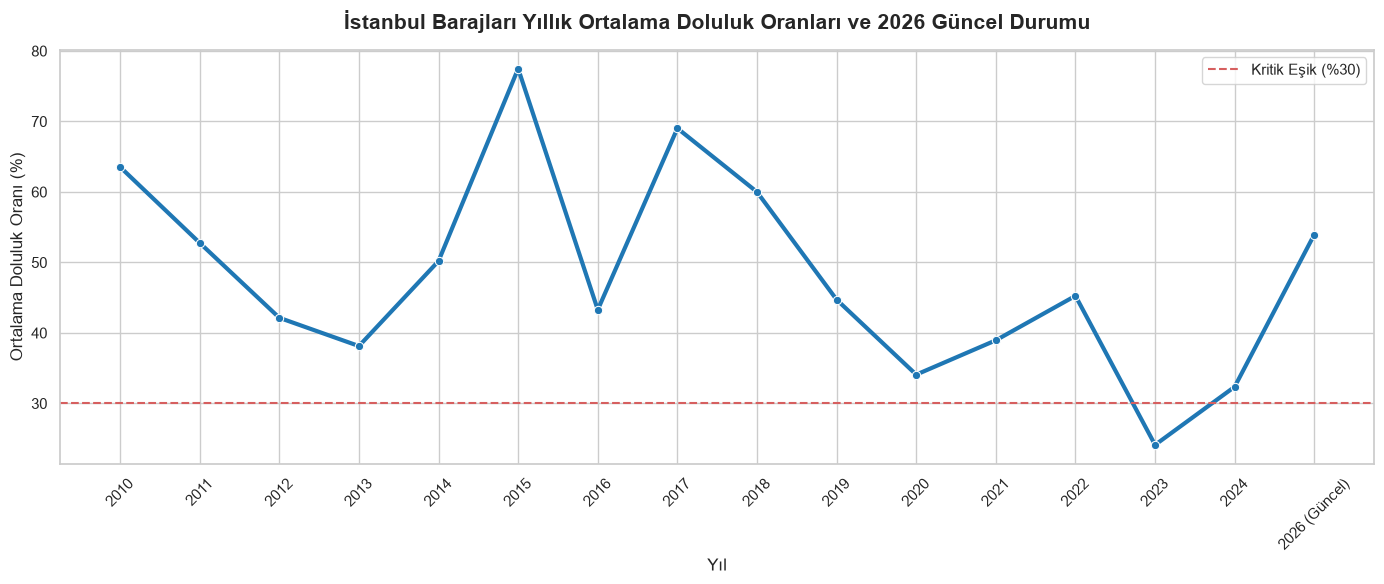

In [3]:
# Aktif veri setlerinin yüklenmesi ve yıllık ortalamaların hesaplanması
df_yillik = pd.read_csv('baraj-yillik-doluluk.csv')
df_istanbul_daily = pd.read_csv('baraj-doluluk-istanbul-1100g.csv')
df_barajlar = pd.read_csv('barajlar.csv')

istanbul_yillik = df_yillik[df_yillik['province_slug'] == 'istanbul'].copy()
years = [str(y) for y in range(2010, 2025)]

df_istanbul_daily['date'] = pd.to_datetime(df_istanbul_daily['date'])
mean_2026 = df_istanbul_daily['fill_rate'].mean()

yillik_ort_series = istanbul_yillik[years].mean(axis=0)
yillik_ort_dict = yillik_ort_series.to_dict()
yillik_ort_dict['2026 (Güncel)'] = mean_2026

# Tablo Formatında Sunum (Önce Tablo)
df_summary_table = pd.DataFrame(list(yillik_ort_dict.items()), columns=['Yıl', 'İstanbul Ortalama Doluluk Oranı (%)'])
print("--- İSTANBUL BARAJLARI YILLIK ORTALAMA DOLULUK TABLOSU (2010 - 2026, 2025 Verisi Hariç) ---")
display(df_summary_table.T)

# Grafik Çizimi (Tablodan Sonra Grafik)
plt.figure(figsize=(14, 6))
sns.lineplot(data=df_summary_table, x='Yıl', y='İstanbul Ortalama Doluluk Oranı (%)', marker='o', color='#1f77b4', linewidth=3)
plt.title('İstanbul Barajları Yıllık Ortalama Doluluk Oranları ve 2026 Güncel Durumu', fontsize=15, fontweight='bold', pad=15)
plt.xlabel('Yıl', fontsize=12)
plt.ylabel('Ortalama Doluluk Oranı (%)', fontsize=12)
plt.xticks(rotation=45)
plt.axhline(y=30, color='r', linestyle='--', label='Kritik Eşik (%30)')
plt.legend()
plt.tight_layout()
plt.show()

### Analitik Değerlendirme ve Açıklama
1. **Tarihsel Seyir ve Kuraklık Dönemleri:** Tablo ve grafik incelendiğinde İstanbul barajlarının yıllık ortalama doluluğunun istikrarlı olmadığı, yıldan yıla büyük dalgalanmalar gösterdiği görülmektedir. Dönemin en yüksek doluluk yılları **2015 (%77.49)** ve **2017 (%69.03)**, en düşük yılları ise **2023 (%24.12)**, **2024 (%32.36)** ve **2020 (%34.08)**'dir. Yıllık ortalamanın %30 kritik eşiğin altına indiği tek yıl 2023'tür; 2020 ve 2024'te ise doluluk bu eşiğe yaklaşmıştır. Doluluk 2013, 2016, 2020 ve 2023 yıllarında önceki ve sonraki yıllara göre dip yapmıştır. Ancak 14 yıllık bir seri, bu diplerin düzenli bir döngü oluşturduğunu söylemek için yeterli değildir.
2. **Veri Notu:** Yıllık ortalamalar, her yıl verisi bulunan barajların basit (kapasiteye göre ağırlıklandırılmamış) ortalamasıdır. Verisi bulunan baraj sayısı 2010-2011'de 6, 2012-2023'te 13, 2024'te 14'tür. Bu nedenle 2010-2011 değerleri sonraki yıllarla tam olarak karşılaştırılabilir değildir. **2025 yılına ait veri, kullanılan veri setlerinde bulunmadığı için o yıldan bağımsız analiz yapılmıştır.**
3. **2026 Yılı Güncel Durum Okuması:** 2026 için hesaplanan ortalama doluluk **%53.96**'dır. Ancak bu değer yalnızca 16 Nisan - 7 Kasım 2026 arasındaki 141 günlük ölçüme dayanır ve barajların beslendiği kış aylarını (ocak-mart) içermez. Bu nedenle grafikte aynı çizgi üzerinde gösterilse de önceki yılların yıllık ortalamalarıyla doğrudan karşılaştırılmamalıdır. 2026'nın yıl içindeki seyri Bölüm 3'te aylık olarak incelenmiştir.

## 3. 2026 Yılı Aylık Bazda Doluluk Analizi (Tablo ve Grafik)
2026 yılına ait günlük veriler (`baraj-doluluk-istanbul-1100g.csv`), aylık bazda gruplandırılarak yıl içindeki mevsimsel dalgalanmalar modellenmiştir. Önce aylık özet tablo verilmiştir.

--- 2026 YILI AYLIK BARAJ DOLULUK ÖZET TABLOSU ---


,Ay,Ölçüm Gün Sayısı,Ortalama Doluluk (%),Minimum Doluluk (%),Maksimum Doluluk (%)
0,2026-04,9,70.600000,70.3,71.1
1,2026-05,4,71.550000,71.1,72.0
2,2026-06,25,67.568000,64.3,70.5
3,2026-07,24,59.508333,54.7,63.7
4,2026-08,22,50.250000,44.3,54.4
5,2026-09,28,39.296429,36.2,43.4
6,2026-10,25,45.608000,37.7,53.8
7,2026-11,4,55.875000,53.7,61.9


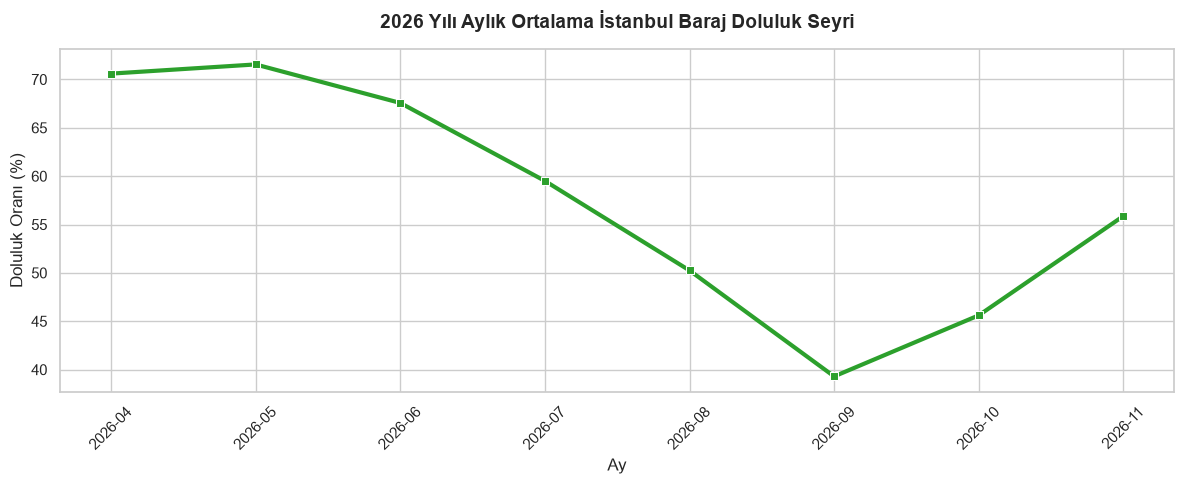

In [4]:
# Aylık ortalamaların hesaplanması
df_istanbul_daily['Ay_Period'] = df_istanbul_daily['date'].dt.to_period('M')
monthly_2026_df = df_istanbul_daily.groupby('Ay_Period')['fill_rate'].agg(['count', 'mean', 'min', 'max']).reset_index()
monthly_2026_df['Ay_Str'] = monthly_2026_df['Ay_Period'].astype(str)
monthly_2026_df.columns = ['Ay_Period', 'Ölçüm Gün Sayısı', 'Ortalama Doluluk (%)', 'Minimum Doluluk (%)', 'Maksimum Doluluk (%)', 'Ay']

# Tablo Gösterimi (Önce Tablo)
print("--- 2026 YILI AYLIK BARAJ DOLULUK ÖZET TABLOSU ---")
display(monthly_2026_df[['Ay', 'Ölçüm Gün Sayısı', 'Ortalama Doluluk (%)', 'Minimum Doluluk (%)', 'Maksimum Doluluk (%)']])

# Grafik Gösterimi (Tablodan Sonra Grafik)
plt.figure(figsize=(12, 5))
sns.lineplot(data=monthly_2026_df, x='Ay', y='Ortalama Doluluk (%)', marker='s', color='#2ca02c', linewidth=3)
plt.title('2026 Yılı Aylık Ortalama İstanbul Baraj Doluluk Seyri', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Ay', fontsize=12)
plt.ylabel('Doluluk Oranı (%)', fontsize=12)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Analitik Değerlendirme ve Açıklama
1. **Bahar Zirvesi:** 2026 yılının en yüksek doluluk seviyeleri nisan (%70.60) ve mayıs (%71.55) aylarında görülmüştür. Bu iki ayın ortalamaları sırasıyla yalnızca 9 ve 4 günlük ölçüme dayandığı için diğer aylara göre daha az temsil edicidir.
2. **Yaz Çekilmesi:** Haziran ayından itibaren doluluk her ay düzenli olarak azalmıştır: haziran %67.57 → temmuz %59.51 → ağustos %50.25 → eylül **%39.30**. Eylül, yılın en düşük aylık ortalamasıdır ve en düşük günlük değer de bu ayda ölçülmüştür (%36.2). Mayıstan eylüle kadar ortalama doluluk yaklaşık 32 puan gerilemiştir.
3. **Sonbahar Toparlanması:** Ekim ayında doluluk yeniden yükselmeye başlamış (ortalama %45.61; ay içindeki en düşük değer %37.7, en yüksek değer %53.8), kasımın ilk günlerinde ortalama %55.88'e ulaşmıştır (4 günlük ölçüm).
4. **İklimle Bağlantı:** Barajların çekildiği haziran-eylül dönemi, Bölüm 4'teki 2020-2025 iklim tablosunda sıcaklığın ve buharlaşma potansiyelinin (ET0) en yüksek, yağışın en düşük olduğu aylara denk gelmektedir. Toparlanmanın başladığı ekim ayı ise yağış sezonunun başlangıcıdır. Yaz aylarında artan su tüketimi de çekilmeye katkı yapmış olabilir; ancak veri setinde tüketim bilgisi bulunmadığından bu etki ölçülememiştir. Bu karşılaştırma 2026 yılının iklim verisiyle değil, önceki yılların mevsimsel düzeniyle yapılmıştır.

## 4. İklim Faktörleri (Sıcaklık, Yağış, Rüzgâr, Buharlaşma Potansiyeli) Aylık Analizi
Bu bölümde İstanbul'a ait **2020-2025** dönemi günlük hava verileri kullanılmıştır. Veriler **Open-Meteo Historical Weather API** üzerinden indirilmiştir ([sorgu bağlantısı](https://open-meteo.com/en/docs/historical-weather-api?latitude=41.0138&longitude=28.9497&timezone=auto&start_date=2010-10-27&daily=temperature_2m_mean,temperature_2m_max,temperature_2m_min,wind_speed_10m_max,wind_gusts_10m_max,wind_direction_10m_dominant,et0_fao_evapotranspiration,sunshine_duration,daylight_duration,precipitation_sum,rain_sum,precipitation_hours,relative_humidity_2m_mean,wind_speed_10m_min,wind_speed_10m_mean,relative_humidity_2m_max,relative_humidity_2m_min)). Sorguda İstanbul için 41.0138° K, 28.9497° D koordinatları girilmiş; API bu noktaya en yakın model ızgara noktasının (41.02° K, 28.89° D, rakım 32 m) verisini döndürmüştür. Veriler `open-meteo-41.02N28.89E32m.csv` dosyası olarak indirilmiş ve notebook'a kaynaktan geldiği haliyle CSV olarak okunmuştur. Kaynakta bulunmayan hiçbir değişken veriye eklenmemiştir.

**Not:** Open-Meteo verileri tek bir meteoroloji istasyonunun ölçümü değildir. Seçilen koordinat için reanaliz (ör. ERA5) tabanlı ızgara verisidir. Bu nedenle değerler MGM istasyon ortalamalarından bir miktar farklı olabilir.

In [5]:
# İstanbul aylık iklim özeti (2020-2025)
# Kaynak: Open-Meteo (https://open-meteo.com) - 41.02° K, 28.89° D, rakım 32 m
# Dosya : open-meteo-41.02N28.89E32m.csv (günlük veri)

# 1) Veriyi okuma
#    CSV'nin ilk 3 satırı konum bilgisi + boş satırdır, bu yüzden atlanır.
#    'time' sütunu tarih olarak okunur (yıl ve ay bilgisini buradan alacağız).
df_meteo = pd.read_csv('open-meteo-41.02N28.89E32m.csv', skiprows=3, parse_dates=['time'])

# 2) Analiz dönemini seçme: 2020-2025 (iki yıl da dahil)
df_meteo = df_meteo[df_meteo['time'].dt.year.between(2020, 2025)].copy()
df_meteo['yil'] = df_meteo['time'].dt.year
df_meteo['ay'] = df_meteo['time'].dt.month

# 3) Veri kontrolü: kullanılacak sütunlarda eksik değer var mı?
kullanilan_sutunlar = [
    'temperature_2m_max (°C)',            # günlük en yüksek sıcaklık
    'precipitation_sum (mm)',             # günlük toplam yağış
    'wind_speed_10m_mean (km/h)',         # günlük ortalama rüzgâr hızı (10 m)
    'et0_fao_evapotranspiration (mm)',    # günlük referans evapotranspirasyon (FAO-56)
]
print("Analize giren gün sayısı:", len(df_meteo))
print("Eksik değer sayısı      :", df_meteo[kullanilan_sutunlar].isna().sum().sum())

# 4) Günlük kayıtları yıl + ay bazında gruplayıp her ayın günlük ortalamasını alma
#    Not: Yağış ve ET0 sütunları "günlük ortalama"dır (mm/gün), aylık toplam DEĞİLDİR.
df_iklim_aylik = (
    df_meteo.groupby(['yil', 'ay'])
    .agg(
        ort_en_yuksek_sicaklik_C=('temperature_2m_max (°C)', 'mean'),
        ort_gunluk_yagis_mm=('precipitation_sum (mm)', 'mean'),
        ort_ruzgar_hizi_kmh=('wind_speed_10m_mean (km/h)', 'mean'),
        ort_gunluk_et0_mm=('et0_fao_evapotranspiration (mm)', 'mean'),
    )
    .round(2)
    .reset_index()
)

# 5) Tablonun gösterimi (72 satırın tamamı görünsün diye satır sınırı kaldırılır)
print("\n--- İSTANBUL AYLIK İKLİM ÖZETİ (2020-2025, Open-Meteo) ---")
with pd.option_context('display.max_rows', None):
    display(df_iklim_aylik)
print("Satır sayısı:", len(df_iklim_aylik))

Analize giren gün sayısı: 2192
Eksik değer sayısı      : 0

--- İSTANBUL AYLIK İKLİM ÖZETİ (2020-2025, Open-Meteo) ---


,yil,ay,ort_en_yuksek_sicaklik_C,ort_gunluk_yagis_mm,ort_ruzgar_hizi_kmh,ort_gunluk_et0_mm
0,2020,1,8.77,4.08,17.37,1.10
1,2020,2,10.90,2.37,17.82,1.73
2,2020,3,12.99,2.29,15.84,2.05
3,2020,4,14.80,1.99,18.55,3.07
4,2020,5,20.69,2.16,13.00,4.00
5,2020,6,25.34,2.38,11.08,4.76
6,2020,7,28.89,0.07,18.71,5.92
7,2020,8,29.55,0.14,17.41,5.73
8,2020,9,27.21,0.59,16.90,4.42
9,2020,10,22.76,2.88,10.83,2.52


Satır sayısı: 72


### Sorgunun Amacı ve Adımları
**Amaç:** Günlük olarak tutulan iklim verisini, baraj doluluk verileriyle karşılaştırılabilecek **aylık** bir özete dönüştürmek ve 2020-2025 döneminde İstanbul'un en sıcak, buharlaşma potansiyeli en yüksek ve en yağışlı dönemlerini belirlemek.

**Adımlar:**
1. **Okuma:** Open-Meteo CSV dosyasının ilk 3 satırı konum bilgisi içerdiği için `skiprows=3` ile atlanmış, `time` sütunu tarih tipinde okunmuştur.
2. **Filtreleme:** Yalnızca 2020-2025 yılları (iki yıl dahil) seçilmiş; tarihten `yil` ve `ay` sütunları türetilmiştir.
3. **Kontrol:** Analize giren gün sayısı (2192 gün = 6 yıl) ve kullanılan sütunlardaki eksik değer sayısı (0) yazdırılarak verinin eksiksiz olduğu doğrulanmıştır.
4. **Gruplama:** Günlük kayıtlar `yil` + `ay` bazında gruplanmış ve her ay için günlük değerlerin **ortalaması** alınmıştır. Sonuç 6 yıl × 12 ay = **72 satırlık** tablodur.

**Sütunların anlamı:**
| Sütun | Kaynaktaki değişken | Anlamı |
|---|---|---|
| `ort_en_yuksek_sicaklik_C` | `temperature_2m_max` | Ay içindeki günlük en yüksek sıcaklıkların ortalaması (°C) |
| `ort_gunluk_yagis_mm` | `precipitation_sum` | Ay içinde günde düşen ortalama yağış (mm/gün). Aylık toplam ≈ değer × ayın gün sayısı |
| `ort_ruzgar_hizi_kmh` | `wind_speed_10m_mean` | 10 m yükseklikteki günlük ortalama rüzgâr hızının aylık ortalaması (km/sa) |
| `ort_gunluk_et0_mm` | `et0_fao_evapotranspiration` | Günlük referans evapotranspirasyonun (FAO-56 Penman-Monteith) aylık ortalaması (mm/gün) |

**ET0 hakkında not:** ET0, atmosferin buharlaştırma talebini gösteren bir göstergedir (sıcaklık, güneş ışınımı, rüzgâr ve nem kullanılarak hesaplanır). Baraj yüzeyinden ölçülmüş gerçek buharlaşma **değildir**. Bu çalışmada "buharlaşma potansiyeli" göstergesi olarak kullanılmıştır.

### Analitik Değerlendirme ve Açıklama
1. **En sıcak aylar:** Dönemin en sıcak ayı **Temmuz 2025**'tir (31.60 °C). Onu Temmuz 2024 (30.99 °C), Ağustos 2023 (30.96 °C) ve Temmuz 2023 (30.90 °C) izlemektedir. Ortalama en yüksek sıcaklığın 30 °C'yi aştığı 6 ayın 5'i **2023-2025** yıllarındadır. Her yıl en sıcak ay temmuz veya ağustostur (2020-2023'te ağustos, 2024-2025'te temmuz).
2. **Buharlaşma potansiyelinin (ET0) en yüksek olduğu aylar:** ET0 her yıl **temmuz** ayında zirve yapmaktadır. Dönemin en yüksek değeri yine **Temmuz 2025**'tir (6.79 mm/gün). Onu Temmuz 2024 (6.35), Haziran 2024 (6.31) ve Temmuz 2023 (6.25) izlemektedir. Temmuz ET0 değeri 2021'den 2025'e her yıl artmıştır (5.61 → 6.10 → 6.25 → 6.35 → 6.79). Ayrıca Haziran 2024 (6.31) ve Haziran 2025 (6.23), 2020-2022 yıllarının temmuz değerlerini aşmıştır. Bu durum, son iki yılda yüksek buharlaşma döneminin daha erken başladığını göstermektedir. Aralık ve ocak aylarında ET0 1.00-1.36 mm/gün aralığındayken temmuz aylarında 5.61-6.79 mm/gün aralığına çıkmaktadır; yani yaz zirvesindeki buharlaşma potansiyeli kışın yaklaşık 5 katıdır.
3. **En yağışlı aylar:** Dönemin açık ara en yağışlı ayı **Kasım 2023**'tür (9.58 mm/gün, ≈ 287 mm aylık toplam). Bu değer ikinci sıradaki Şubat 2022'nin (5.50 mm/gün) yaklaşık 1.7 katıdır. Onu Aralık 2024 (5.22), Ocak 2021 (4.80) ve Ekim 2025 (4.46) izlemektedir. Her yılın en yağışlı ayı **Ekim-Şubat** aralığına düşmektedir. Yani barajları besleyen ana yağış dönemi sonbahar ve kıştır.
4. **En kurak aylar ve 2025 yazı:** En düşük yağış **Temmuz 2025**'te görülmüştür (0.01 mm/gün). 2025, haziran-temmuz-ağustos aylarının üçünde de yağışın 0.08 mm/gün veya altında kaldığı tek yıldır. Temmuz 2025, dönemin en yüksek sıcaklığı, en yüksek ET0 değeri ve en düşük yağışını aynı ayda birleştirmektedir. Bu nedenle incelenen dönemin iklimsel açıdan en zorlu ayıdır.
5. **Mevsimsel karşıtlık:** Tabloda sıcaklık ve ET0 yaz aylarında zirve yaparken yağış en düşük seviyededir. Yağışın en yüksek olduğu ekim-şubat döneminde ise ET0 en düşüktür. Bu karşıtlık her yıl tekrarlanmaktadır. Ancak tüm yazlar tamamen kurak değildir: Temmuz 2021 (1.27 mm/gün), Ağustos 2022 (1.60 mm/gün) ve Eylül 2024 (3.22 mm/gün) bu kalıbın istisnalarıdır.

**Yorum sınırı:** Bu tablo yalnızca iklim koşullarını özetler. Baraj doluluğuyla ilişkisi bu tablodan doğrudan çıkarılamaz; baraj verisiyle birlikte ayrıca incelenmelidir. Ayrıca ET0 hesabında sıcaklık kullanıldığı için sıcaklık ile ET0 arasındaki yüksek ilişki kısmen hesaplama yönteminden kaynaklanır. Bu ilişki tek başına bir bulgu olarak yorumlanmamalıdır.

In [6]:
# İstanbul barajları yıllık doluluk (2010-2024) + yıllık iklim ortalamaları (Open-Meteo)

# 1) Baraj tablosu: Bölüm 2'de hesaplanan yıllık ortalamalar (yillik_ort_series) kullanılır.
#    Her yıl kaç barajın verisi olduğu da eklenir, çünkü baraj sayısı yıllara göre değişiyor.
df_baraj_yillik = pd.DataFrame({
    'yil': yillik_ort_series.index.astype(int),
    'baraj_sayisi': istanbul_yillik[years].count().values,
    'ort_doluluk_yuzde': yillik_ort_series.values,
})

# 2) İklim verisi: Bölüm 4'teki tablo 2020-2025'e filtrelendiği için ham CSV yeniden okunur.
df_meteo_tum = pd.read_csv('open-meteo-41.02N28.89E32m.csv', skiprows=3, parse_dates=['time'])
print("Meteoroloji verisinin ilk günü:", df_meteo_tum['time'].min().date())

# 3) Yalnızca tam yıllar alınır: veri 27.10.2010'da başladığı için 2010 yılı eksiktir
#    (sadece 66 gün, yalnızca sonbahar-kış). Bu nedenle iklim ortalamaları 2011-2024 için hesaplanır.
df_meteo_tum = df_meteo_tum[df_meteo_tum['time'].dt.year.between(2011, 2024)]

# 4) Yıllık özet: sıcaklık ve ET0 için günlük değerlerin ortalaması, yağış için yıllık TOPLAM
df_iklim_yillik = (
    df_meteo_tum.groupby(df_meteo_tum['time'].dt.year.rename('yil'))
    .agg(
        ort_en_yuksek_sicaklik_C=('temperature_2m_max (°C)', 'mean'),
        ort_gunluk_et0_mm=('et0_fao_evapotranspiration (mm)', 'mean'),
        toplam_yagis_mm=('precipitation_sum (mm)', 'sum'),   # YENİ: yıllık toplam yağış
    )
    .reset_index()
)

# 5) Birleştirme (left join): baraj tablosundaki 15 yılın hepsi korunur, 2010'un iklim değerleri boş (NaN) kalır.
df_baraj_iklim = df_baraj_yillik.merge(df_iklim_yillik, on='yil', how='left')

# 6) Bir önceki yıla göre değişimler (azalan yılları karşılaştırmak için)
df_baraj_iklim['doluluk_degisimi_puan'] = df_baraj_iklim['ort_doluluk_yuzde'].diff()
df_baraj_iklim['sicaklik_degisimi_C'] = df_baraj_iklim['ort_en_yuksek_sicaklik_C'].diff()
df_baraj_iklim['et0_degisimi_mm'] = df_baraj_iklim['ort_gunluk_et0_mm'].diff()
df_baraj_iklim['yagis_degisimi_mm'] = df_baraj_iklim['toplam_yagis_mm'].diff()   # YENİ
df_baraj_iklim = df_baraj_iklim.round(2)

print("\n--- İSTANBUL BARAJLARI YILLIK DOLULUK VE İKLİM ORTALAMALARI (2010-2024) ---")
display(df_baraj_iklim)

print("\n--- DOLULUK ORANININ BİR ÖNCEKİ YILA GÖRE AZALDIĞI YILLAR ---")
display(df_baraj_iklim[df_baraj_iklim['doluluk_degisimi_puan'] < 0])

print(f"2011-2024 ortalaması -> en yüksek sıcaklık: {df_baraj_iklim['ort_en_yuksek_sicaklik_C'].mean():.2f} °C"
      f" | ET0: {df_baraj_iklim['ort_gunluk_et0_mm'].mean():.2f} mm/gün"
      f" | yağış: {df_baraj_iklim['toplam_yagis_mm'].mean():.1f} mm/yıl")   # YENİ

Meteoroloji verisinin ilk günü: 2010-10-27

--- İSTANBUL BARAJLARI YILLIK DOLULUK VE İKLİM ORTALAMALARI (2010-2024) ---


,yil,baraj_sayisi,ort_doluluk_yuzde,ort_en_yuksek_sicaklik_C,ort_gunluk_et0_mm,toplam_yagis_mm,doluluk_degisimi_puan,sicaklik_degisimi_C,et0_degisimi_mm,yagis_degisimi_mm
0,2010,6,63.54,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2011,6,52.77,16.75,2.94,572.1,-10.77,NaN,NaN,NaN
2,2012,13,42.15,18.39,3.21,582.1,-10.63,1.64,0.27,10.0
3,2013,13,38.14,18.35,3.17,507.2,-4.01,-0.04,-0.04,-74.9
4,2014,13,50.20,18.43,2.93,733.6,12.06,0.08,-0.25,226.4
5,2015,13,77.49,17.91,2.96,696.4,27.29,-0.52,0.03,-37.2
6,2016,13,43.28,18.27,3.19,738.3,-34.21,0.36,0.23,41.9
7,2017,13,69.03,18.33,3.00,692.4,25.75,0.06,-0.19,-45.9
8,2018,13,60.00,19.13,2.98,801.2,-9.03,0.80,-0.02,108.8
9,2019,13,44.72,19.34,3.16,596.2,-15.28,0.21,0.18,-205.0



--- DOLULUK ORANININ BİR ÖNCEKİ YILA GÖRE AZALDIĞI YILLAR ---


,yil,baraj_sayisi,ort_doluluk_yuzde,ort_en_yuksek_sicaklik_C,ort_gunluk_et0_mm,toplam_yagis_mm,doluluk_degisimi_puan,sicaklik_degisimi_C,et0_degisimi_mm,yagis_degisimi_mm
1,2011,6,52.77,16.75,2.94,572.1,-10.77,NaN,NaN,NaN
2,2012,13,42.15,18.39,3.21,582.1,-10.63,1.64,0.27,10.0
3,2013,13,38.14,18.35,3.17,507.2,-4.01,-0.04,-0.04,-74.9
6,2016,13,43.28,18.27,3.19,738.3,-34.21,0.36,0.23,41.9
8,2018,13,60.00,19.13,2.98,801.2,-9.03,0.80,-0.02,108.8
9,2019,13,44.72,19.34,3.16,596.2,-15.28,0.21,0.18,-205.0
10,2020,13,34.08,19.23,3.19,632.6,-10.64,-0.11,0.03,36.4
13,2023,13,24.12,19.81,3.18,928.6,-21.15,1.11,0.01,285.5


2011-2024 ortalaması -> en yüksek sıcaklık: 18.67 °C | ET0: 3.10 mm/gün | yağış: 687.9 mm/yıl


### Sorgunun Amacı ve Adımları
**Amaç:** İstanbul barajlarının 2010-2024 yıllık ortalama doluluk oranlarını, aynı yılların ortalama en yüksek sıcaklık, buharlaşma potansiyeli (ET0) ve toplam yağış değerleriyle tek tabloda birleştirmek; doluluğun azaldığı yıllarda iklim koşullarının nasıl olduğunu karşılaştırmak.

**Adımlar:**
1. Bölüm 2'de hesaplanan yıllık doluluk ortalamaları (`yillik_ort_series`) tabloya dönüştürülmüş, her yıl kaç barajın verisi bulunduğu (`baraj_sayisi`) eklenmiştir.
2. Open-Meteo CSV dosyası yeniden okunmuştur. Bölüm 4'teki tablo 2020-2025'e filtrelendiği için ham veriye geri dönmek gerekmiştir.
3. Meteoroloji verisi 27 Ekim 2010'da başladığından 2010 yılında yalnızca 66 gün (sonbahar-kış) vardır. Bu yılın ortalaması yanıltıcı olacağı için iklim ortalamaları **2011-2024** tam yılları için hesaplanmıştır.
4. Günlük en yüksek sıcaklık ve günlük ET0 değerlerinin yıllık **ortalamaları**, günlük yağışın ise yıllık **toplamı** (mm/yıl) alınmıştır.
5. İki tablo `yil` sütunu üzerinden **left join** (`merge(how='left')`) ile birleştirilmiştir. Böylece baraj tablosundaki 15 yılın hepsi korunmuş, 2010'un iklim değerleri boş (NaN) kalmıştır.
6. Her değişken için bir önceki yıla göre fark (`diff()`) hesaplanmış, doluluğun azaldığı yıllar ayrı bir tabloda gösterilmiştir.

### Analitik Değerlendirme ve Açıklama
**Önce iki veri uyarısı:**
- **Baraj sayısı yıllara göre değişiyor.** 2010-2011'de 6, 2012-2023'te 13, 2024'te 14 barajın verisi vardır. Bu nedenle 2011→2012 düşüşü (-10.63 puan) ve 2023→2024 artışı (+8.25 puan) kısmen ortalamaya giren baraj kümesinin değişmesinden kaynaklanır; iklimle doğrudan karşılaştırılmamalıdır. Ayrıca ortalama, barajların kapasitesine göre ağırlıklandırılmamıştır (küçük ve büyük barajlar eşit ağırlıktadır).
- **2011'in iklim değişimi hesaplanamıyor**, çünkü 2010'un iklim verisi eksiktir.

Bu nedenle aşağıdaki karşılaştırma, baraj sayısının sabit (13) olduğu **2013-2023** dönemine odaklanmaktadır.

1. **Doluluğun azaldığı yıllar:** Bu dönemde doluluk 6 yılda azalmıştır: 2013 (-4.01), 2016 (-34.21), 2018 (-9.03), 2019 (-15.28), 2020 (-10.64) ve 2023 (-21.15 puan). En sert iki düşüş 2016 ve 2023'tür. 2016 düşüşü, dönemin en yüksek doluluk yılı olan 2015'in (%77.49) ardından gelmiştir.

2. **Azalan yıllarda sıcaklık:** Bu 6 yılın 4'ünde ortalama en yüksek sıcaklık bir önceki yıla göre artmıştır (2016 +0.36, 2018 +0.80, 2019 +0.21, 2023 +1.11 °C). En belirgin örnek **2023**'tür: sıcaklıktaki +1.11 °C'lik artış 2013-2023 döneminin en büyük yıllık sıcaklık artışıdır ve aynı yıl doluluk dönemin en düşük seviyesine (%24.12) inmiştir. Ancak 2013 (-0.04 °C) ve 2020 (-0.11 °C) yıllarında sıcaklık artmadığı hâlde doluluk yine düşmüştür. 2018'de ise sıcaklık belirgin biçimde artmış (+0.80 °C), doluluk düşmesine rağmen %60.00 ile yüksek seviyede kalmıştır.

3. **Azalan yıllarda buharlaşma potansiyeli (ET0):** ET0'ın yıldan yıla değişimi çok küçüktür (çoğu yıl ±0.25 mm/gün içinde). Azalan 6 yılın 4'ünde ET0 artmış veya aynı kalmıştır (2016 +0.23, 2019 +0.18, 2020 +0.03, 2023 +0.01). Değişimlerin yalnızca yönlerine bakmak net bir sonuç vermemektedir; ilişkinin gücü aşağıdaki 4.1 bölümünde grafikler ve korelasyon katsayısı ile ayrıca ölçülmüştür.

4. **ET0 seviyesi ile doluluk seviyesi arasındaki ayrışma (en belirgin bulgu):** Değişimler yerine yılların ET0 seviyelerine bakıldığında daha net bir tablo ortaya çıkmaktadır. Bu madde ve 5. madde yılların kendi seviyelerini karşılaştırdığı için 2011-2024 yıllarının hepsi dahil edilmiştir; 2011 ve 2024'te baraj kümesinin farklı olduğu yine akılda tutulmalıdır.
   - ET0'ın **3.00 mm/gün veya altında** kaldığı yıllarda (2011, 2014, 2015, 2017, 2018) doluluk her zaman **%50'nin üzerindedir** (%50.20-%77.49). Dönemin en yüksek doluluk yılları olan 2015 (%77.49), 2017 (%69.03) ve 2018 (%60.00) bu gruptadır.
   - ET0'ın **3.15 mm/gün ve üzerinde** olduğu yıllarda (2012, 2013, 2016, 2019, 2020, 2022, 2023, 2024) doluluk her zaman **%46'nın altındadır** (%24.12-%45.26). Dönemin en düşük doluluk yılları olan 2023 (%24.12), 2024 (%32.36) ve 2020 (%34.08) bu gruptadır.
   - Arada kalan tek yıl 2021'dir (ET0 3.07, doluluk %38.95).

5. **Sıcaklık seviyesi:** 2011-2024 ortalaması 18.67 °C'dir. Ortalama en yüksek sıcaklığın 19 °C'yi aştığı 5 yılın (2018, 2019, 2020, 2023, 2024) 4'ünde doluluk %45'in altındadır. İstisna 2018'dir (%60.00). En sıcak iki yıl olan 2024 (20.07 °C) ve 2023 (19.81 °C), aynı zamanda dönemin en düşük iki doluluk yılıdır. Ayrıca 2018-2024 yıllarının her biri, 2011-2017 döneminin en sıcak yılından (2014, 18.43 °C) daha sıcaktır.

6. **Yağış (takvim yılı toplamı):** 2011-2024 ortalaması 687.9 mm/yıl'dır. Doluluğun azaldığı 6 yılın yalnızca 2'sinde yağış da azalmıştır: **2013** (-74.9 mm; 507.2 mm ile dönemin en kurak yılı) ve **2019** (-205.0 mm). Bu iki yılda düşük yağış ile doluluk düşüşü örtüşmektedir. Diğer 4 yılda ise yağış artmasına rağmen doluluk düşmüştür (2016, 2018, 2020, 2023). En çarpıcı örnek **2023**'tür: 928.6 mm ile dönemin **en yağışlı** yılı olmasına rağmen doluluk dönemin **en düşük** seviyesindedir (%24.12). Bölüm 4'teki aylık tablo bunun nedenini göstermektedir: 2023 yağışının yaklaşık üçte biri tek bir ayda, **Kasım 2023**'te düşmüştür (9.58 mm/gün ≈ 287 mm). Yani yağış yılın sonunda, kurak geçen aylardan sonra gelmiş ve o yılın ortalama doluluğunu yükseltememiştir. Ertesi yıl (2024) doluluk +8.25 puan artmıştır (bu artışın bir kısmı baraj sayısının 14'e çıkmasından kaynaklanabilir).

   **Bu bulgunun anlamı:** Takvim yılı yağış toplamı, aynı yılın ortalama doluluğunu tek başına açıklamamaktadır. Doluluğu belirleyen, yağışın yıl içinde **ne zaman** düştüğüdür. Barajları besleyen ana dönem sonbahar-kış aylarıdır (Bölüm 4). Bu nedenle daha doğru bir karşılaştırma için yağışın "su yılı" (Ekim-Eylül) bazında toplanması gerekir. Bu iyileştirme Gelecek Çalışmalar kapsamındadır.

**Sonuç ve yorum sınırı:** Yüksek sıcaklık ve yüksek buharlaşma potansiyeli olan yıllar, düşük doluluk yıllarıyla büyük ölçüde örtüşmektedir. Takvim yılı yağışı ise doluluk değişimiyle tutarlı bir ilişki göstermemektedir; bunun başlıca nedeni yağışın yıl içindeki zamanlamasıdır. Bulunan örtüşmeler **eş zamanlılıktır, nedensellik kanıtı değildir**. 14 yıllık kısa bir seride baraj doluluğunu belirleyen başka etkenler de vardır: şehrin su tüketimi ve Melen/Yeşilçay gibi dış kaynaklardan yapılan su transferleri. Bu değişkenler tabloda yer almadığı için ilişkinin büyüklüğü bu analizle kesin olarak belirlenemez.

### 4.1 Grafiklerle Baraj Doluluğu - İklim İlişkisi
Yukarıdaki birleştirilmiş tablodan (`df_baraj_iklim`) iki soruya grafiklerle yanıt aranmıştır:
1. **Buharlaşma potansiyelinin (ET0) yüksek olduğu yıllarda baraj doluluğu azalmış mı?**
2. **Yağışın yüksek olduğu yıllarda baraj doluluğunda olumlu bir gelişme olmuş mu?**

İlk kod hücresinde grafikler için veri hazırlanmış ve ilişkilerin gücü korelasyon katsayısı (Pearson r) ile ölçülmüştür. r, -1 ile +1 arasında değer alır: -1'e yakın değerler güçlü ters yönlü, +1'e yakın değerler güçlü aynı yönlü ilişkiyi, 0'a yakın değerler ise ilişki olmadığını gösterir. İki karşılaştırma yapılmıştır:
- **Doluluk seviyesi:** 2011-2024 (14 yıl; 2010'un iklim verisi eksik).
- **Doluluk değişimi:** 2013-2023 (11 yıl). Yalnızca baraj sayısının sabit (13) olduğu yıllar alınmıştır, çünkü 2012 ve 2024'teki değişimler kısmen baraj sayısının değişmesinden kaynaklanır.

In [7]:
# Grafikler için veri hazırlığı ve korelasyon katsayıları

# 1) Seviye karşılaştırması için: iklim verisi olan tüm yıllar (2011-2024)
df_grafik_seviye = df_baraj_iklim[df_baraj_iklim['yil'].between(2011, 2024)].copy()

# 2) Değişim karşılaştırması için: baraj sayısının sabit (13) olduğu yıllar (2013-2023)
df_grafik_degisim = df_baraj_iklim[df_baraj_iklim['yil'].between(2013, 2023)].copy()

# 3) Dönem ortalamaları (yılları "yüksek" / "düşük" diye ayırmak için eşik olarak kullanılacak)
et0_ort = df_grafik_seviye['ort_gunluk_et0_mm'].mean()
yagis_ort = df_grafik_seviye['toplam_yagis_mm'].mean()
print(f"2011-2024 ortalamaları -> ET0: {et0_ort:.2f} mm/gün | yağış: {yagis_ort:.1f} mm/yıl")

# 4) Korelasyon katsayıları (Pearson r)
korelasyon_tablosu = pd.DataFrame([
    ['ET0 - Doluluk seviyesi', '2011-2024', len(df_grafik_seviye),
     df_grafik_seviye['ort_gunluk_et0_mm'].corr(df_grafik_seviye['ort_doluluk_yuzde'])],
    ['ET0 - Doluluk değişimi', '2013-2023', len(df_grafik_degisim),
     df_grafik_degisim['ort_gunluk_et0_mm'].corr(df_grafik_degisim['doluluk_degisimi_puan'])],
    ['Yağış - Doluluk seviyesi', '2011-2024', len(df_grafik_seviye),
     df_grafik_seviye['toplam_yagis_mm'].corr(df_grafik_seviye['ort_doluluk_yuzde'])],
    ['Yağış - Doluluk değişimi', '2013-2023', len(df_grafik_degisim),
     df_grafik_degisim['toplam_yagis_mm'].corr(df_grafik_degisim['doluluk_degisimi_puan'])],
], columns=['İlişki', 'Dönem', 'Yıl Sayısı', 'Korelasyon (r)']).round(2)
print("\n--- KORELASYON KATSAYILARI ---")
display(korelasyon_tablosu)

# 5) Ortalamanın üstündeki ve altındaki yıllarda ortalama doluluk (2011-2024)
ust_et0 = df_grafik_seviye['ort_gunluk_et0_mm'] >= et0_ort
ust_yagis = df_grafik_seviye['toplam_yagis_mm'] >= yagis_ort
grup_tablosu = pd.DataFrame({
    'Değişken': ['ET0', 'Yağış'],
    'Ortalamanın üstündeki yıllarda doluluk (%)': [
        df_grafik_seviye.loc[ust_et0, 'ort_doluluk_yuzde'].mean(),
        df_grafik_seviye.loc[ust_yagis, 'ort_doluluk_yuzde'].mean(),
    ],
    'Ortalamanın altındaki yıllarda doluluk (%)': [
        df_grafik_seviye.loc[~ust_et0, 'ort_doluluk_yuzde'].mean(),
        df_grafik_seviye.loc[~ust_yagis, 'ort_doluluk_yuzde'].mean(),
    ],
}).round(2)
print("\n--- ORTALAMANIN ÜSTÜ / ALTI YILLARDA ORTALAMA DOLULUK (2011-2024) ---")
display(grup_tablosu)

2011-2024 ortalamaları -> ET0: 3.10 mm/gün | yağış: 687.9 mm/yıl

--- KORELASYON KATSAYILARI ---


,İlişki,Dönem,Yıl Sayısı,Korelasyon (r)
0,ET0 - Doluluk seviyesi,2011-2024,14,-0.75
1,ET0 - Doluluk değişimi,2013-2023,11,-0.72
2,Yağış - Doluluk seviyesi,2011-2024,14,-0.12
3,Yağış - Doluluk değişimi,2013-2023,11,-0.17



--- ORTALAMANIN ÜSTÜ / ALTI YILLARDA ORTALAMA DOLULUK (2011-2024) ---


,Değişken,Ortalamanın üstündeki yıllarda doluluk (%),Ortalamanın altındaki yıllarda doluluk (%)
0,ET0,38.01,58.07
1,Yağış,49.43,42.85


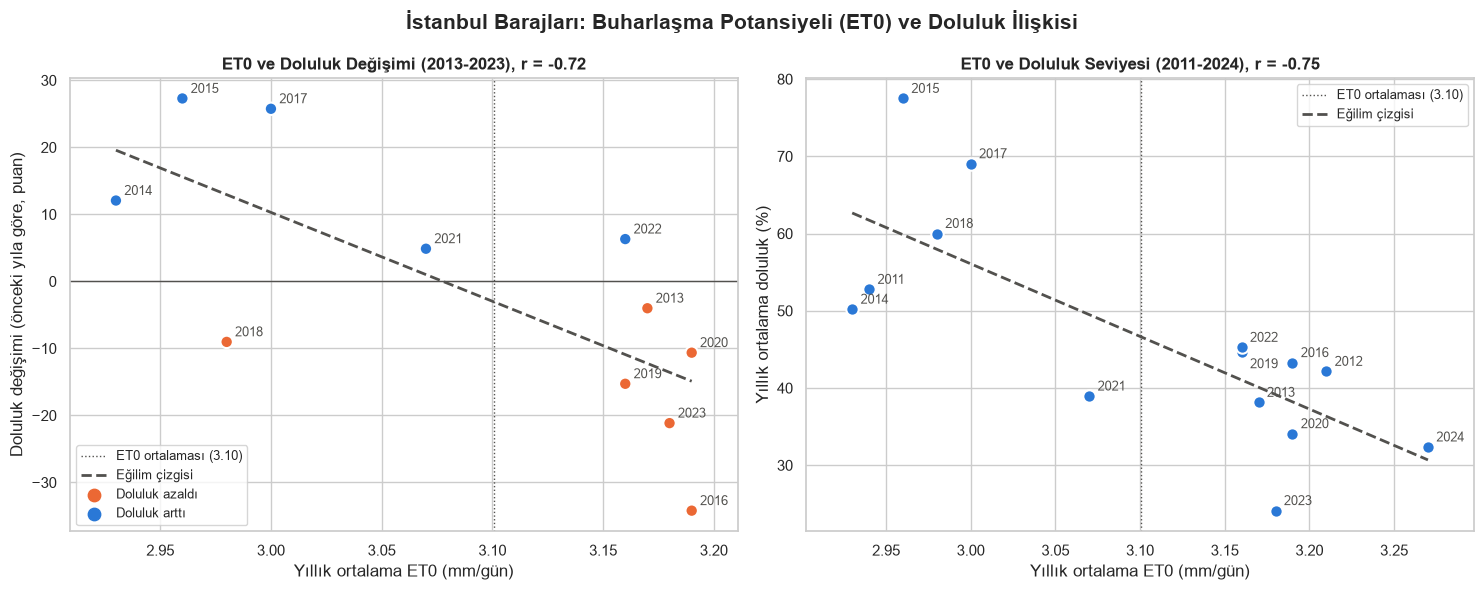

In [8]:
# Grafik 1: Buharlaşma potansiyeli (ET0) yüksek olan yıllarda baraj doluluğu azalmış mı?
MAVI, TURUNCU, GRI = '#2a78d6', '#eb6834', '#52514e'
# Üst üste binen yıl etiketleri için özel konumlar (varsayılan: noktanın sağ üstü)
kaydir_sol, kaydir_sag = {}, {2019: (6, -12)}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# Sol panel: ET0 ve doluluğun bir önceki yıla göre değişimi (2013-2023)
renkler = [TURUNCU if v < 0 else MAVI for v in df_grafik_degisim['doluluk_degisimi_puan']]
ax1.scatter(df_grafik_degisim['ort_gunluk_et0_mm'], df_grafik_degisim['doluluk_degisimi_puan'],
            c=renkler, s=80, edgecolor='white', linewidth=1.5, zorder=3)
for _, satir in df_grafik_degisim.iterrows():
    ax1.annotate(int(satir['yil']), (satir['ort_gunluk_et0_mm'], satir['doluluk_degisimi_puan']),
                 xytext=kaydir_sol.get(int(satir['yil']), (6, 4)), textcoords='offset points', fontsize=9, color=GRI)
ax1.axhline(0, color=GRI, linewidth=1)
ax1.axvline(et0_ort, color=GRI, linewidth=1, linestyle=':', label=f'ET0 ortalaması ({et0_ort:.2f})')
# Eğilim çizgisi (doğrusal regresyon)
egim, kesisim = np.polyfit(df_grafik_degisim['ort_gunluk_et0_mm'], df_grafik_degisim['doluluk_degisimi_puan'], 1)
x_cizgi = np.linspace(df_grafik_degisim['ort_gunluk_et0_mm'].min(), df_grafik_degisim['ort_gunluk_et0_mm'].max(), 50)
ax1.plot(x_cizgi, egim * x_cizgi + kesisim, color=GRI, linestyle='--', linewidth=2, label='Eğilim çizgisi')
ax1.scatter([], [], c=TURUNCU, s=80, label='Doluluk azaldı')
ax1.scatter([], [], c=MAVI, s=80, label='Doluluk arttı')
ax1.legend(loc='lower left', fontsize=9)
ax1.set_title(f"ET0 ve Doluluk Değişimi (2013-2023), r = {korelasyon_tablosu.loc[1, 'Korelasyon (r)']}",
              fontsize=12, fontweight='bold')
ax1.set_xlabel('Yıllık ortalama ET0 (mm/gün)')
ax1.set_ylabel('Doluluk değişimi (önceki yıla göre, puan)')

# Sağ panel: ET0 ve doluluk seviyesi (2011-2024)
ax2.scatter(df_grafik_seviye['ort_gunluk_et0_mm'], df_grafik_seviye['ort_doluluk_yuzde'],
            color=MAVI, s=80, edgecolor='white', linewidth=1.5, zorder=3)
for _, satir in df_grafik_seviye.iterrows():
    ax2.annotate(int(satir['yil']), (satir['ort_gunluk_et0_mm'], satir['ort_doluluk_yuzde']),
                 xytext=kaydir_sag.get(int(satir['yil']), (6, 4)), textcoords='offset points', fontsize=9, color=GRI)
ax2.axvline(et0_ort, color=GRI, linewidth=1, linestyle=':', label=f'ET0 ortalaması ({et0_ort:.2f})')
egim, kesisim = np.polyfit(df_grafik_seviye['ort_gunluk_et0_mm'], df_grafik_seviye['ort_doluluk_yuzde'], 1)
x_cizgi = np.linspace(df_grafik_seviye['ort_gunluk_et0_mm'].min(), df_grafik_seviye['ort_gunluk_et0_mm'].max(), 50)
ax2.plot(x_cizgi, egim * x_cizgi + kesisim, color=GRI, linestyle='--', linewidth=2, label='Eğilim çizgisi')
ax2.legend(loc='upper right', fontsize=9)
ax2.set_title(f"ET0 ve Doluluk Seviyesi (2011-2024), r = {korelasyon_tablosu.loc[0, 'Korelasyon (r)']}",
              fontsize=12, fontweight='bold')
ax2.set_xlabel('Yıllık ortalama ET0 (mm/gün)')
ax2.set_ylabel('Yıllık ortalama doluluk (%)')

for ax in (ax1, ax2):
    ax.margins(x=0.08)   # kenardaki etiketler kesilmesin

fig.suptitle('İstanbul Barajları: Buharlaşma Potansiyeli (ET0) ve Doluluk İlişkisi',
             fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

### Grafik 1'in Amacı
Bu grafikte, **buharlaşma potansiyelinin (ET0) yüksek olduğu yıllarda baraj doluluğunun azalıp azalmadığı** incelenmiştir.
- **Sol panel:** Her nokta bir yılı gösterir. Yatay eksen o yılın ortalama ET0 değeri, dikey eksen doluluğun bir önceki yıla göre değişimidir. Turuncu noktalar doluluğun azaldığı, mavi noktalar arttığı yıllardır. Dikey noktalı çizginin sağı "yüksek ET0" yıllarını, yatay sıfır çizgisinin altı "doluluğun azaldığı" yılları gösterir. Hipotez doğruysa turuncu noktalar sağ altta toplanmalıdır.
- **Sağ panel:** Aynı soruya doluluk seviyesi üzerinden bakar. ET0 yüksek olan yıllarda yıllık ortalama doluluğun düşük olması beklenir.
- Kesikli çizgi doğrusal eğilim çizgisidir; başlıklardaki r değeri ilişkinin gücünü gösterir.

### Analitik Değerlendirme ve Açıklama
**Sonuç: ET0 ile baraj doluluğu arasında belirgin, ters yönlü bir ilişki vardır.**

1. **Doluluk değişimi (sol panel, r = -0.72):** ET0'ın dönem ortalamasının (3.10 mm/gün) üzerinde olduğu 6 yılın **5'inde doluluk azalmıştır**: 2013, 2016, 2019, 2020 ve 2023. Tek istisna 2022'dir (+6.31 puan). ET0'ın ortalamanın altında kaldığı 5 yılın ise **4'ünde doluluk artmıştır**: 2014, 2015, 2017 ve 2021. Tek istisna 2018'dir (-9.03 puan). Turuncu noktaların sağ altta, mavi noktaların sol üstte toplanması hipotezi destekler.
2. **Doluluk seviyesi (sağ panel, r = -0.75):** ET0'ın ortalamanın üzerinde olduğu yıllarda ortalama doluluk **%38.01**, altında olduğu yıllarda **%58.07**'dir; aradaki fark yaklaşık 20 puandır. Dönemin en dolu yılları (2015, 2017, 2018) grafiğin sol üstünde, en düşük doluluklu yılları (2023, 2024, 2020) sağ altındadır.
3. **İstisnalar başlangıç seviyesinin önemini gösterir:** 2018'de ET0 düşük olduğu hâlde doluluk azalmıştır, ancak bu düşüş %69.03 gibi yüksek bir seviyeden (2017) gelmiştir ve doluluk yine %60.00'ta kalmıştır. 2022'de ise ET0 yüksek olduğu hâlde doluluk, %38.95 gibi düşük bir seviyeden (2021) toparlanmıştır.

**İlişkinin mantıksal açıklaması:** ET0 tek başına "buharlaşan su miktarı" değildir. Sıcaklık, güneşlenme, rüzgâr ve kuru havanın birleşik bir göstergesidir. ET0'ın yüksek olduğu yıllar sıcak, güneşli ve kuru geçen yıllardır. Bu koşullar barajları birkaç yoldan etkiler:
- Baraj yüzeyinden doğrudan buharlaşma artar.
- Havzadaki toprak kurur; düşen yağışın daha büyük kısmı toprak tarafından tutulur ve barajlara daha az su ulaşır.
- Sıcak yıllarda şehrin su tüketimi de genellikle artar. Bu etken veri setinde yer almadığı için ölçülememiştir.

**Yorum sınırı:** Bu ilişki **nedensellik kanıtı değildir**. Seri kısadır (11-14 yıl). Ayrıca dönem boyunca ET0 artarken doluluk azalma eğilimindedir; iki değişkenin aynı anda zamanla değişmesi korelasyonu kısmen büyütüyor olabilir. ET0 baraj yüzeyinden ölçülmüş gerçek buharlaşma değil, bir göstergedir.

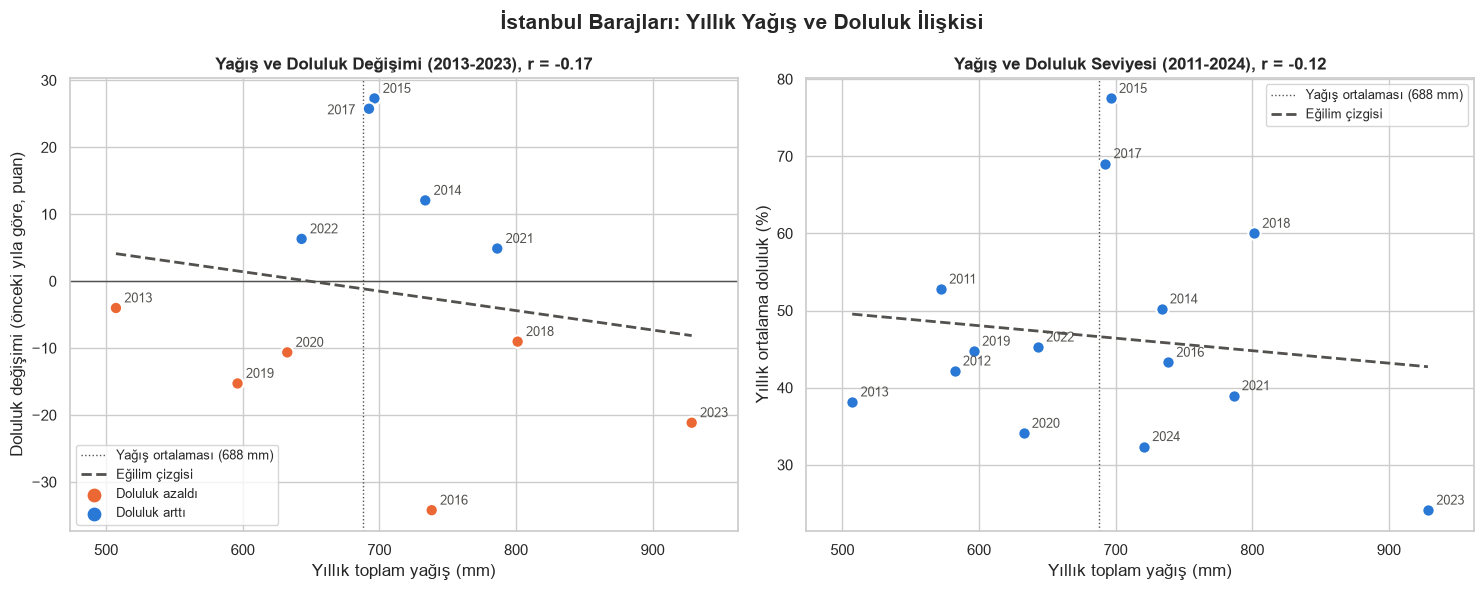

In [9]:
# Grafik 2: Yağışın yüksek olduğu yıllarda baraj doluluğunda olumlu bir gelişme olmuş mu?
MAVI, TURUNCU, GRI = '#2a78d6', '#eb6834', '#52514e'
# Üst üste binen yıl etiketleri için özel konumlar (varsayılan: noktanın sağ üstü)
kaydir_sol, kaydir_sag = {2017: (-30, -4)}, {}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# Sol panel: yıllık yağış ve doluluğun bir önceki yıla göre değişimi (2013-2023)
renkler = [TURUNCU if v < 0 else MAVI for v in df_grafik_degisim['doluluk_degisimi_puan']]
ax1.scatter(df_grafik_degisim['toplam_yagis_mm'], df_grafik_degisim['doluluk_degisimi_puan'],
            c=renkler, s=80, edgecolor='white', linewidth=1.5, zorder=3)
for _, satir in df_grafik_degisim.iterrows():
    ax1.annotate(int(satir['yil']), (satir['toplam_yagis_mm'], satir['doluluk_degisimi_puan']),
                 xytext=kaydir_sol.get(int(satir['yil']), (6, 4)), textcoords='offset points', fontsize=9, color=GRI)
ax1.axhline(0, color=GRI, linewidth=1)
ax1.axvline(yagis_ort, color=GRI, linewidth=1, linestyle=':', label=f'Yağış ortalaması ({yagis_ort:.0f} mm)')
# Eğilim çizgisi (doğrusal regresyon)
egim, kesisim = np.polyfit(df_grafik_degisim['toplam_yagis_mm'], df_grafik_degisim['doluluk_degisimi_puan'], 1)
x_cizgi = np.linspace(df_grafik_degisim['toplam_yagis_mm'].min(), df_grafik_degisim['toplam_yagis_mm'].max(), 50)
ax1.plot(x_cizgi, egim * x_cizgi + kesisim, color=GRI, linestyle='--', linewidth=2, label='Eğilim çizgisi')
ax1.scatter([], [], c=TURUNCU, s=80, label='Doluluk azaldı')
ax1.scatter([], [], c=MAVI, s=80, label='Doluluk arttı')
ax1.legend(loc='lower left', fontsize=9)
ax1.set_title(f"Yağış ve Doluluk Değişimi (2013-2023), r = {korelasyon_tablosu.loc[3, 'Korelasyon (r)']}",
              fontsize=12, fontweight='bold')
ax1.set_xlabel('Yıllık toplam yağış (mm)')
ax1.set_ylabel('Doluluk değişimi (önceki yıla göre, puan)')

# Sağ panel: yıllık yağış ve doluluk seviyesi (2011-2024)
ax2.scatter(df_grafik_seviye['toplam_yagis_mm'], df_grafik_seviye['ort_doluluk_yuzde'],
            color=MAVI, s=80, edgecolor='white', linewidth=1.5, zorder=3)
for _, satir in df_grafik_seviye.iterrows():
    ax2.annotate(int(satir['yil']), (satir['toplam_yagis_mm'], satir['ort_doluluk_yuzde']),
                 xytext=kaydir_sag.get(int(satir['yil']), (6, 4)), textcoords='offset points', fontsize=9, color=GRI)
ax2.axvline(yagis_ort, color=GRI, linewidth=1, linestyle=':', label=f'Yağış ortalaması ({yagis_ort:.0f} mm)')
egim, kesisim = np.polyfit(df_grafik_seviye['toplam_yagis_mm'], df_grafik_seviye['ort_doluluk_yuzde'], 1)
x_cizgi = np.linspace(df_grafik_seviye['toplam_yagis_mm'].min(), df_grafik_seviye['toplam_yagis_mm'].max(), 50)
ax2.plot(x_cizgi, egim * x_cizgi + kesisim, color=GRI, linestyle='--', linewidth=2, label='Eğilim çizgisi')
ax2.legend(loc='upper right', fontsize=9)
ax2.set_title(f"Yağış ve Doluluk Seviyesi (2011-2024), r = {korelasyon_tablosu.loc[2, 'Korelasyon (r)']}",
              fontsize=12, fontweight='bold')
ax2.set_xlabel('Yıllık toplam yağış (mm)')
ax2.set_ylabel('Yıllık ortalama doluluk (%)')

for ax in (ax1, ax2):
    ax.margins(x=0.08)   # kenardaki etiketler kesilmesin

fig.suptitle('İstanbul Barajları: Yıllık Yağış ve Doluluk İlişkisi',
             fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

### Grafik 2'nin Amacı
Bu grafikte, **yağışın yüksek olduğu yıllarda baraj doluluğunda olumlu bir gelişme olup olmadığı** incelenmiştir. Grafik, Grafik 1 ile aynı düzende hazırlanmıştır:
- **Sol panel:** Yatay eksen yıllık toplam yağış, dikey eksen doluluğun bir önceki yıla göre değişimidir. Hipotez doğruysa yağışın ortalamanın (688 mm) üzerinde olduğu yıllarda (noktalı çizginin sağı) noktalar sıfır çizgisinin üstünde (mavi) olmalıdır.
- **Sağ panel:** Yağışlı yıllarda yıllık ortalama doluluğun yüksek olması beklenir.

### Analitik Değerlendirme ve Açıklama
**Sonuç: Yıllık yağış toplamı ile baraj doluluğu arasında anlamlı bir ilişki görülmemektedir.** Korelasyon katsayıları sıfıra yakındır ve beklenenin aksine hafif negatiftir (değişim için r = -0.17, seviye için r = -0.12).

1. **Yağışlı yıllar:** Yağışın ortalamanın üzerinde olduğu 7 yılın 4'ünde doluluk artmış (2014, 2015, 2017, 2021), 3'ünde ise azalmıştır (2016, 2018, 2023). Yani yağışlı bir yıl, doluluğun artacağını garanti etmemektedir.
2. **Kurak yıllar:** Yağışın ortalamanın altında kaldığı 4 yılın 3'ünde doluluk azalmıştır (2013, 2019, 2020). Kurak yıllarda düşüş beklentisi kısmen doğrulanmaktadır.
3. **Seviye:** Yağışlı yıllarda ortalama doluluk %49.43, kurak yıllarda %42.85'tir. Fark beklenen yöndedir, ancak küçüktür ve yıllar arasında tutarlı değildir.
4. **Eğilim çizgisini aşağı çeken yıl 2023'tür:** Dönemin en yağışlı yılı (928.6 mm) aynı zamanda en düşük doluluklu yılıdır (%24.12) ve doluluk 21.15 puan düşmüştür.

### İlişkinin Görülmemesinin Olası Nedenleri
Fiziksel olarak barajların ana su girdisi yağıştır; dolayısıyla yağışın doluluğu etkilemediği sonucuna varılamaz. Ancak bu veri yapısında yağışın beklenen etkisini görmeyi zorlaştıran etkenler vardır:

1. **Yağışın zamanlaması (en önemli neden):** Takvim yılı toplamı, yağışın yıl içinde ne zaman düştüğünü göstermez. Bölüm 4'teki aylık tabloya göre 2023 yağışının yaklaşık üçte biri tek bir ayda, Kasım 2023'te düşmüştür (≈ 287 mm). Yılın büyük bölümü kurak geçtiği için yıllık ortalama doluluk düşük kalmış; yıl sonundaki yağışın etkisi ise ancak ertesi yıla yansıyabilmiştir. Barajları besleyen dönem ekim-mart arasıdır ve takvim yılını ikiye böler.
2. **Yüksek buharlaşmanın yağışın etkisini maskelemesi:** 2023, hem en yağışlı hem de ET0'ı yüksek (3.18 mm/gün) ve dönemin en sıcak ikinci yılıdır (19.81 °C). Grafik 1'de görülen güçlü buharlaşma etkisi, yağışın olumlu etkisini aynı yıl içinde dengelemiş olabilir.
3. **Önceki yılın doluluk seviyesi:** 2016'da yağış ortalamanın üzerinde (738.3 mm) olduğu hâlde doluluk 34.21 puan düşmüştür. Ancak bir önceki yıl (2015) dönemin rekor doluluğu (%77.49) yaşanmıştır. Barajlar doluyken fazla su dolusavaklardan bırakılır; bu nedenle çok yüksek bir seviyeden sonra yağışlı bir yıl bile düşüşü önleyemeyebilir.
4. **Yağışın ölçüldüğü yer:** Meteoroloji verisi tek bir ızgara noktasına (41.02° K, 28.89° D) aittir. Barajların su toplama havzaları ise kentin farklı bölgelerine dağılmıştır. Havzalara düşen yağış bu noktadakinden farklı olabilir.
5. **Yağışın şekli:** Kısa sürede düşen şiddetli yağışın önemli bir kısmı toprağa sızmadan yüzey akışıyla kaybolabilir. Kurak dönemlerden sonra ise ilk yağışları kuru toprak emer ve barajlara ulaşan su azalır.
6. **Veride bulunmayan insan kaynaklı etkenler:** Kentin su tüketimi (nüfus artışı, yaz talebi), Melen ve Yeşilçay gibi dış kaynaklardan yapılan su transferleri ve İSKİ'nin işletme kararları doluluğu doğrudan etkiler. Örneğin barajlar düştüğünde transferlerin artırılması, yağışın etkisini perdeleyebilir.
7. **Veri yapısının sınırları:** Doluluk yıllık ortalama olduğundan yıl içindeki dalgalanmaları gizler. Ortalama kapasiteye göre ağırlıklandırılmamıştır ve seri yalnızca 11-14 yıldır.

**Sonuç:** Yağış ve buharlaşma, baraj su miktarını doğrudan etkilemesi beklenen faktörlerdir. Ancak yıllık toplam yağış, yukarıdaki etkenler nedeniyle bu analizde beklenen etkiyi gösterememektedir. Yağışın etkisinin doğru ölçülebilmesi için aylık doluluk verisi, su yılı (Ekim-Eylül) bazında yağış ve yağışın doluluğa gecikmeli etkisinin incelenmesi gerekir. Bu iyileştirmeler Gelecek Çalışmalar kapsamındadır.

## 5. Baraj Bazlı Güncel Doluluk ve Risk Gruplandırması
Bu bölümde aktif veri setlerinden `barajlar.csv` dosyasındaki güncel ölçümler (**9 Kasım 2026**) kullanılarak İstanbul barajları doluluk oranlarına göre risk gruplarına ayrılmıştır. Tablolar elle girilmemiş; doğrudan veri setinden kodla hesaplanmıştır. Her barajın doluluk oranının yanında kapasitesi ve mevcut su miktarı da gösterilerek risk gruplarının toplam su arzı içindeki ağırlığı ortaya konmuştur.

In [10]:
# İstanbul barajları güncel doluluk ve risk gruplandırması (kaynak: barajlar.csv)

# 1) İstanbul barajlarını seçme
#    barajlar.csv Bölüm 2'de df_barajlar olarak okunmuştu. İstanbul'daki 16 kaydın 6'sı (DSİ kayıtları)
#    güncel doluluk ölçümü içermediği için yalnızca doluluk değeri olan barajlar alınır.
df_ist_barajlar = df_barajlar[
    (df_barajlar['province_slug'] == 'istanbul') & (df_barajlar['fill_rate'].notna())
].copy()

# 2) Ölçüm tarihi (tablodaki değerler bu ana aittir)
df_ist_barajlar['olcum_tarihi'] = pd.to_datetime(df_ist_barajlar['measured_at']).dt.date
print("Ölçüm tarihi:", df_ist_barajlar['olcum_tarihi'].unique())

# 3) Risk grupları (bu çalışmada belirlenen eşikler):
#    %20'nin altı: Kritik | %20 - %60 arası: Orta/Yüksek | %60 ve üzeri: Güvenli
df_ist_barajlar['risk_grubu'] = pd.cut(
    df_ist_barajlar['fill_rate'],
    bins=[0, 20, 60, float('inf')],
    right=False,   # aralıklar [0,20), [20,60), [60,∞)
    labels=['Kritik Risk (< %20)', 'Orta / Yüksek Risk (%20 - %60)', 'Güvenli (≥ %60)'],
)

# 4) Baraj bazlı tablo: doluluğa göre küçükten büyüğe sıralı
df_risk_baraj = (
    df_ist_barajlar[['name', 'risk_grubu', 'fill_rate', 'capacity_hm3', 'volume_hm3']]
    .sort_values('fill_rate')
    .rename(columns={
        'name': 'Baraj',
        'risk_grubu': 'Risk Grubu',
        'fill_rate': 'Doluluk (%)',
        'capacity_hm3': 'Kapasite (milyon m³)',
        'volume_hm3': 'Mevcut Su (milyon m³)',
    })
    .reset_index(drop=True)
)
print("\n--- İSTANBUL BARAJLARI GÜNCEL DOLULUK VE RİSK GRUBU ---")
display(df_risk_baraj)

# 5) Risk grubu özeti: her grupta kaç baraj var ve toplam kapasitenin ne kadarını oluşturuyor
df_risk_ozet = (
    df_risk_baraj.groupby('Risk Grubu', observed=True)
    .agg(
        baraj_sayisi=('Baraj', 'count'),
        barajlar=('Baraj', ', '.join),
        toplam_kapasite_hm3=('Kapasite (milyon m³)', 'sum'),
        toplam_mevcut_su_hm3=('Mevcut Su (milyon m³)', 'sum'),
    )
    .reset_index()
)
df_risk_ozet['kapasite_payi_yuzde'] = (
    df_risk_ozet['toplam_kapasite_hm3'] / df_risk_ozet['toplam_kapasite_hm3'].sum() * 100
)
df_risk_ozet = df_risk_ozet.round(2)
print("\n--- RİSK GRUBU ÖZETİ ---")
with pd.option_context('display.max_colwidth', None):
    display(df_risk_ozet)

# 6) Genel doluluk: kapasiteye göre ağırlıklı (toplam su / toplam kapasite) ve ağırlıksız (basit ortalama)
toplam_doluluk = df_ist_barajlar['volume_hm3'].sum() / df_ist_barajlar['capacity_hm3'].sum() * 100
basit_ortalama = df_ist_barajlar['fill_rate'].mean()
print(f"\nİstanbul toplam doluluk (kapasiteye göre ağırlıklı): %{toplam_doluluk:.1f}")
print(f"Barajların basit (ağırlıksız) doluluk ortalaması : %{basit_ortalama:.1f}")

Ölçüm tarihi: [datetime.date(2026, 11, 9)]

--- İSTANBUL BARAJLARI GÜNCEL DOLULUK VE RİSK GRUBU ---


,Baraj,Risk Grubu,Doluluk (%),Kapasite (milyon m³),Mevcut Su (milyon m³)
0,Papuçdere Barajı,Kritik Risk (< %20),7.8,35.222,2.76
1,Kazandere Barajı,Kritik Risk (< %20),12.3,21.096,2.59
2,Büyükçekmece Barajı,Orta / Yüksek Risk (%20 - %60),41.2,129.892,53.48
3,Sazlıdere Barajı,Orta / Yüksek Risk (%20 - %60),42.9,88.730,38.02
4,Terkos Gölü,Orta / Yüksek Risk (%20 - %60),51.8,195.974,101.54
5,Elmalı Barajı,Güvenli (≥ %60),69.1,9.600,6.63
6,Alibey Barajı,Güvenli (≥ %60),79.6,34.143,27.17
7,Ömerli Barajı,Güvenli (≥ %60),83.0,244.540,202.85
8,Istrancalar,Güvenli (≥ %60),84.7,6.231,5.27
9,Darlık Barajı,Güvenli (≥ %60),94.6,102.463,96.96



--- RİSK GRUBU ÖZETİ ---


,Risk Grubu,baraj_sayisi,barajlar,toplam_kapasite_hm3,toplam_mevcut_su_hm3,kapasite_payi_yuzde
0,Kritik Risk (< %20),2,"Papuçdere Barajı, Kazandere Barajı",56.32,5.35,6.49
1,Orta / Yüksek Risk (%20 - %60),3,"Büyükçekmece Barajı, Sazlıdere Barajı, Terkos Gölü",414.60,193.04,47.77
2,Güvenli (≥ %60),5,"Elmalı Barajı, Alibey Barajı, Ömerli Barajı, Istrancalar, Darlık Barajı",396.98,338.88,45.74



İstanbul toplam doluluk (kapasiteye göre ağırlıklı): %61.9
Barajların basit (ağırlıksız) doluluk ortalaması : %56.7


### Sorgunun Amacı ve Adımları
1. `barajlar.csv` (Bölüm 2'de `df_barajlar` olarak okunmuştu) içinden İstanbul barajları seçilmiştir. İstanbul'a ait 16 kaydın 6'sı DSİ kaydıdır ve güncel doluluk ölçümü içermediği için analize alınmamıştır; analize **10 baraj** girmiştir.
2. Doluluk oranına göre `pd.cut()` ile üç risk grubu oluşturulmuştur. Eşikler bu çalışmada belirlenmiştir: **%20'nin altı Kritik**, **%20-%60 Orta/Yüksek**, **%60 ve üzeri Güvenli**.
3. Baraj bazlı tablo doluluk oranına göre sıralanmış, ardından her risk grubunun baraj sayısı, toplam kapasitesi, mevcut suyu ve toplam kapasite içindeki payı hesaplanmıştır.
4. Son olarak genel doluluk iki yöntemle hesaplanmıştır: kapasiteye göre ağırlıklı (toplam mevcut su / toplam kapasite) ve basit (ağırlıksız) ortalama.

### Analitik Değerlendirme ve Açıklama
1. **Kritik Risk Grubu:** **Papuçdere (%7.8)** ve **Kazandere (%12.3)** İstanbul'un en düşük doluluklu barajlarıdır. Ancak bu iki barajın toplam kapasitesi 56.32 milyon m³'tür ve İstanbul'un toplam baraj kapasitesinin yalnızca **%6.49**'unu oluşturur. Şu anda içlerinde toplam 5.35 milyon m³ su bulunmaktadır. Yani doluluk oranları alarm verici olsa da kentin toplam su arzına etkileri sınırlıdır.
2. **Orta / Yüksek Risk Grubu:** **Büyükçekmece (%41.2)**, **Sazlıdere (%42.9)** ve **Terkos Gölü (%51.8)** bu gruptadır. Bu grup, toplam kapasitenin **%47.77**'si (414.60 milyon m³) ile **en büyük kapasite payına** sahiptir. Terkos Gölü (195.97 milyon m³) tek başına İstanbul'un ikinci büyük su kaynağıdır. Bu nedenle kentin su güvenliği açısından asıl izlenmesi gereken grup, doluluk oranı en düşük olan kritik grup değil, kapasitesi en büyük olan bu gruptur.
3. **Güvenli Grup:** **Elmalı (%69.1)**, **Alibey (%79.6)**, **Ömerli (%83.0)**, **Istrancalar (%84.7)** ve **Darlık (%94.6)** bu gruptadır ve toplam kapasitenin %45.74'ünü oluşturur. Grubun ağırlığını büyük ölçüde **Ömerli** belirler: 244.54 milyon m³ ile İstanbul'un en büyük barajıdır ve şu anda 202.85 milyon m³ su içermektedir. Bu, tüm barajlardaki toplam suyun yaklaşık %38'idir.
4. **Ağırlıklı ve ağırlıksız doluluk farkı:** Kapasiteye göre ağırlıklı toplam doluluk **%61.9**, barajların basit ortalaması ise **%56.7**'dir. Fark, büyük barajların (Ömerli, Darlık) küçük barajlardan daha dolu olmasından kaynaklanır. Bu sonuç, Bölüm 2'deki yıllık ortalamaların da ağırlıksız hesaplandığını ve bu nedenle küçük barajların etkisinin olduğundan fazla göründüğünü hatırlatmaktadır.

**Not:** Bu tablo yalnızca 9 Kasım 2026 tarihindeki anlık durumu gösterir. Melen ve Yeşilçay gibi dış kaynaklardan yapılan su transferleri bu veri setinde yer almadığı için analize dahil edilmemiştir.

## 6. Kritik Dönemler İçin Stratejik Önlemler ve Politika Önerileri
Baraj doluluk oranlarının %30 kritik eşiğin altına gerilediği kuraklık senaryolarında İSKİ ve yerel yönetimlerin hayata geçirmesi gereken yapısal ve operasyonel tedbirler şunlardır:

1. **Basınç Optimizasyonu ve Akıllı Şebeke Yönetimi:** Şebeke hatlarında gece saatlerinde kademeli basınç düşürülmesi sağlanarak yüksek basınçlı patlaklar ve su kayıp-kaçak oranları minimize edilmelidir.
2. **Melen ve Yeşilçay Entegrasyonunun Maksimizasyonu:** Yerel barajlardaki çekilme hızlandığında, Sakarya Melen sistemi üzerinden transfer edilen hammadde su miktarı tam kapasiteye çıkarılmalıdır.
3. **Kademeli ve Caydırıcı Su Tarifesi:** Bireysel ve sanayi tüketimlerinde aşırı su kullanımını önlemek amacıyla kademeli artan fiyat tarifeleri uygulanmalı, su bilinci kampanyaları yaygınlaştırılmalıdır.
4. **Gri Su Geri Kazanım Zorunluluğu:** Yeni inşa edilen toplu konut projelerinde ve sanayi tesislerinde gri su (lavabo/duş sularının arıtılarak rezervuarlarda ve peyzaj sulamada kullanılması) sistemleri yasal zorunluluk haline getirilmelidir.
5. **Bilinçli Tüketimi Teşvik:** Su tüketiminde bilinçlenmeyi sağlamak maksatlı mevcut eğitimler risk faktörleri görselleştirilerek geliştirilmelidir. Bilinçli tüketime dair teşvikler için sosyal medya, kamu spotu, film ve dizi sektörü (örneğin senaryoya bilinçli su tüketimini dahil etme) gibi araçlara başvurulmalıdır.

## 7. Tüm Analiz Sonuçları
Bu çalışmada İstanbul barajlarının 2010-2024 yıllık doluluk oranları, 2026 günlük doluluk verileri ve güncel baraj bazlı ölçümler; Open-Meteo'dan alınan günlük sıcaklık, yağış ve buharlaşma potansiyeli (ET0) verileriyle birlikte incelenmiştir. Analizlerden elde edilen sonuçlar aşağıda özetlenmiştir.

### 7.1 Barajların Uzun Dönem Doluluk Seyri (Bölüm 2)
- İstanbul barajlarının yıllık ortalama doluluğu yıldan yıla büyük dalgalanmalar göstermektedir. Dönemin en yüksek doluluk yılları **2015 (%77.49)** ve **2017 (%69.03)**, en düşük yılları **2023 (%24.12)**, **2024 (%32.36)** ve **2020 (%34.08)**'dir. Yıllık ortalamanın %30 kritik eşiğinin altına indiği tek yıl 2023'tür.
- Baraj sayısının sabit (13) olduğu yıllar karşılaştırıldığında, tablodaki değerlerin ortalaması **2012-2019 döneminde %53.1** iken **2020-2023 döneminde %35.6**'ya düşmüştür. Bu, son yıllarda barajların belirgin biçimde daha düşük doluluk seviyelerinde seyrettiğini göstermektedir.

### 7.2 Yıl İçi (Mevsimsel) Doluluk Seyri: 2026 (Bölüm 3)
- 2026 verisi 16 Nisan - 7 Kasım arasını kapsar. Doluluk nisan-mayıs aylarında **%71 civarında** zirve yapmış, haziran ayından itibaren her ay düşerek **eylülde %39.30**'a (en düşük günlük değer %36.2) inmiştir. Ekim ayında toparlanma başlamış (%45.61), kasımın ilk günlerinde %55.88'e yükselmiştir.
- Bu seyir, Bölüm 4'te görülen iklim mevsimselliğiyle aynı zamana denk gelmektedir: barajların çekildiği haziran-eylül dönemi, sıcaklığın ve buharlaşma potansiyelinin en yüksek, yağışın en düşük olduğu dönemdir; toparlanmanın başladığı ekim ayı ise yağış sezonunun başlangıcıdır.
- 2026 dönem ortalaması (%53.96) kış aylarını içermediği için önceki yılların yıllık ortalamalarıyla doğrudan karşılaştırılmamalıdır.

### 7.3 İklim Koşulları (Bölüm 4)
- **Sıcaklık:** 2018-2024 yıllarının her biri, 2011-2017 döneminin en sıcak yılından (18.43 °C) daha sıcaktır. Dönemin en sıcak iki yılı 2024 (20.07 °C) ve 2023 (19.81 °C), en sıcak ayı Temmuz 2025'tir (31.60 °C).
- **Buharlaşma potansiyeli (ET0):** ET0 her yıl temmuzda zirve yapmakta ve yaz zirvesi kış değerlerinin yaklaşık 5 katına çıkmaktadır. Temmuz ET0 değeri 2021'den 2025'e her yıl artmıştır (5.61 → 6.79 mm/gün).
- **Yağış:** Her yılın en yağışlı ayı ekim-şubat aralığındadır; barajları besleyen ana dönem sonbahar ve kıştır. Dönemin en yağışlı ayı Kasım 2023 (≈ 287 mm), en kurak yazı ise üç ayı da neredeyse yağışsız geçen 2025 yazıdır.

### 7.4 Baraj Doluluğu ile İklim İlişkisi (Bölüm 4 ve 4.1)
- **Buharlaşma potansiyeli (ET0) ile güçlü ve ters yönlü bir ilişki bulunmuştur** (doluluk seviyesiyle r = -0.75, doluluk değişimiyle r = -0.72). ET0'ın ortalamanın üzerinde olduğu yıllarda ortalama doluluk %38.01, altında olduğu yıllarda %58.07'dir. 2013-2023 arasında ET0'ın yüksek olduğu 6 yılın 5'inde doluluk azalmıştır. ET0; sıcaklık, güneşlenme, rüzgâr ve kuru havanın birleşik göstergesi olduğu için bu sonuç, **sıcak ve kurak geçen yılların barajlar için en olumsuz yıllar olduğunu** göstermektedir.
- **Sıcaklık** da doluluğun düştüğü yıllarla örtüşmektedir: en sıcak iki yıl (2023, 2024) aynı zamanda en düşük doluluklu iki yıldır.
- **Yıllık toplam yağış ile anlamlı bir ilişki bulunamamıştır** (r = -0.12 ve -0.17). Bunun başlıca nedenleri: yağışın yıl içinde ne zaman düştüğünün takvim yılı toplamında kaybolması (2023 en yağışlı yıl olduğu hâlde en düşük doluluklu yıldır; yağışın üçte biri kasım ayında düşmüştür), aynı yıl yüksek buharlaşmanın yağışın etkisini dengelemesi, önceki yılın doluluk seviyesi, yağışın tek bir noktada ölçülmesi ve veride bulunmayan tüketim ile su transferleridir. Bu nedenle sonuç "yağış doluluğu etkilemez" şeklinde değil, **"yağışın etkisi yıllık toplam veriyle ölçülemez"** şeklinde yorumlanmalıdır.

### 7.5 Güncel Durum ve Risk (Bölüm 5)
- 9 Kasım 2026 itibarıyla İstanbul barajlarının kapasiteye göre ağırlıklı toplam doluluğu **%61.9**'dur.
- Doluluk oranı en düşük barajlar Papuçdere (%7.8) ve Kazandere (%12.3) olsa da bu iki baraj toplam kapasitenin yalnızca %6.49'unu oluşturur. **Kentin su güvenliği açısından asıl izlenmesi gereken grup**, toplam kapasitenin %47.77'sini tutan ve %20-60 doluluk aralığında bulunan Terkos Gölü, Büyükçekmece ve Sazlıdere barajlarıdır.

### 7.6 Genel Değerlendirme
İstanbul'un baraj rezervleri hem yıl içinde hem de yıllar arasında iklim koşullarına duyarlıdır. Yıl içinde barajlar her yaz sıcaklık ve buharlaşmanın arttığı dönemde çekilmekte, sonbahar-kış yağışlarıyla toparlanmaktadır. Yıllar arasında ise sıcaklığın ve buharlaşma potansiyelinin yüksek olduğu yıllar, doluluğun düşük olduğu yıllarla tutarlı biçimde örtüşmektedir. Son yıllarda hem sıcaklıkların hem de yaz buharlaşma potansiyelinin artması ve aynı dönemde ortalama doluluğun düşmesi, iklim koşullarının İstanbul'un su güvenliği üzerindeki baskısının arttığına işaret etmektedir. Bu bulgular, Bölüm 6'daki önlemlerin özellikle sıcak ve kurak geçmesi beklenen yıllardan önce devreye alınmasının önemini desteklemektedir.

### 7.7 Çalışmanın Sınırlılıkları
- Yıllık seri kısadır (14 yıl); bulunan ilişkiler eş zamanlılıktır ve nedensellik kanıtı değildir.
- Yıllık doluluk ortalamaları barajların kapasitesine göre ağırlıklandırılmamıştır ve ortalamaya giren baraj sayısı yıllara göre değişmektedir (6, 13 ve 14).
- 2025 yılına ait baraj doluluk verisi bulunmamaktadır; 2026 verisi ise yalnızca nisan-kasım dönemini kapsamaktadır.
- Meteoroloji verisi tek bir ızgara noktasına ait reanaliz verisidir; barajların havzalarına düşen yağışı tam olarak temsil etmeyebilir. ET0, baraj yüzeyinden ölçülmüş gerçek buharlaşma değildir.
- Kentin su tüketimi ve Melen/Yeşilçay gibi dış kaynaklardan yapılan su transferleri veri setlerinde yer almamaktadır.

### 7.8 Gelecek Çalışmalar
- **Makine öğrenmesi ile doluluk tahmini:** Geçmiş yılların baraj doluluk oranları, dönemsel sıcaklık ortalamaları, ET0 ve mevsimsel hava tahminleri bir makine öğrenmesi modeline verilerek önümüzdeki aylarda barajların doluluk oranının tahmin edilmesi hedeflenmektedir.
- Bu model için doluluk verisinin **aylık** çözünürlükte toplanması, yağışın **su yılı (Ekim-Eylül)** bazında hesaplanması ve yağışın doluluğa **gecikmeli etkisinin** (ör. önceki 3-6 ayın yağışı) değişken olarak eklenmesi planlanmaktadır.
- Yıllık doluluk ortalamalarının kapasiteye göre ağırlıklı hesaplanması, havza bazlı yağış verisinin kullanılması ve su tüketimi ile transfer verilerinin analize eklenmesi sonuçların güvenilirliğini artıracaktır.

## 8. Kaynaklar ve Referanslar
Bu analiz çalışmasında kullanılan açık veri platformları aşağıda listelenmiştir:

1. **Açık Veri ve Baraj Doluluk Verileri:** Baraj doluluk oranları, API servisleri ve CSV verilerinin indirildiği platform: [dolulukorani.com Veri Portalı](https://www.dolulukorani.com/veri)
2. **Meteorolojik Veriler:** İstanbul'a ait günlük sıcaklık, yağış, rüzgâr ve referans evapotranspirasyon (ET0) verilerinin indirildiği kaynak: [Open-Meteo Historical Weather API](https://open-meteo.com/en/docs/historical-weather-api?latitude=41.0138&longitude=28.9497&timezone=auto&start_date=2010-10-27&daily=temperature_2m_mean,temperature_2m_max,temperature_2m_min,wind_speed_10m_max,wind_gusts_10m_max,wind_direction_10m_dominant,et0_fao_evapotranspiration,sunshine_duration,daylight_duration,precipitation_sum,rain_sum,precipitation_hours,relative_humidity_2m_mean,wind_speed_10m_min,wind_speed_10m_mean,relative_humidity_2m_max,relative_humidity_2m_min) (41.0138° K, 28.9497° D; başlangıç tarihi 27.10.2010). Open-Meteo verileri CC BY 4.0 lisansı ile sunulmaktadır.